# 01 — Data Validation & Exploratory Data Analysis

Notebook này thực hiện bước đầu tiên của quá trình hiểu dữ liệu:

1. Xác định chiến lược đọc dữ liệu phù hợp với giới hạn tài nguyên.
2. Kiểm tra cấu trúc và schema của các raw datasets.
3. Kiểm tra chất lượng dữ liệu.
4. Kiểm tra quan hệ giữa các bảng và tính nhất quán theo thời gian.
5. Kiểm tra target `sales`.
6. Thực hiện Exploratory Data Analysis (EDA).
7. Tổng hợp các phát hiện và quyết định cho `02_data_cleaning.ipynb`.

> **Nguyên tắc:** notebook này chủ yếu *phát hiện và mô tả vấn đề*. Không sửa trực tiếp dữ liệu trong `data/raw/`.

## 0. Notebook Scope & Configuration

Các cấu hình trong notebook này phải phù hợp với kết quả từ
`00_scope_and_environment.ipynb`.

Đặc biệt, `train.csv` không được mặc định load toàn bộ vào RAM.

In [1]:
from pathlib import Path
import os
import sys
import platform
import time
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import psutil
except ImportError:
    psutil = None

# Resolve project root from either project root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    if (PROJECT_ROOT.parent / "data" / "raw").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
TARGET_COLUMN = "unit_sales"

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_DIR)
print("Target:", TARGET_COLUMN)

Project root: /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast
Raw data: /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast/data/raw
Target: unit_sales


### Notebook Configuration Notes

- Raw datasets are read-only inputs.
- Large files are processed with chunks where appropriate.
- Aggregations are preferred over retaining the full `train.csv` DataFrame.
- Any cleaning or transformation intended for the actual pipeline belongs to `02_data_cleaning.ipynb`.

## 1. Data Loading Strategy

Trước khi validation và EDA, xác định cách đọc từng dataset.

Nguyên tắc:

- Các bảng nhỏ có thể đọc toàn bộ.
- `train.csv` được xử lý theo chunk.
- Các thống kê cần cho EDA được aggregate rồi giải phóng từng chunk.
- Không tạo nhiều bản sao lớn của `train.csv` trong RAM.

In [2]:
csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))

inventory = []
for path in csv_files:
    inventory.append({
        "file": path.name,
        "size_mb": path.stat().st_size / (1024**2),
    })

file_inventory_df = (
    pd.DataFrame(inventory)
    .sort_values("size_mb", ascending=False)
    .reset_index(drop=True)
)

file_inventory_df

,file,size_mb
0,train.csv,4765.941895
1,test.csv,120.318438
2,sample_submission.csv,38.571913
3,transactions.csv,1.480710
4,items.csv,0.097123
5,holidays_events.csv,0.021276
6,oil.csv,0.019627
7,stores.csv,0.001323


In [3]:
# Conservative starting value. Benchmark/adjust if needed.
DEFAULT_CHUNK_SIZE = 100_000

print(f"Starting chunk size: {DEFAULT_CHUNK_SIZE:,} rows")
print("This is not a final project-wide constant.")

Starting chunk size: 100,000 rows
This is not a final project-wide constant.


### Loading Strategy — Initial Decision

`train.csv` là dataset lớn nhất. Do đó, notebook này không sử dụng
`pd.read_csv(train.csv)` để giữ toàn bộ dữ liệu trong RAM.

Các bảng nhỏ hơn sẽ được load full nếu kiểm tra kích thước cho thấy điều đó an toàn.

In [4]:
small_tables = {}

for filename in [
    "stores.csv",
    "items.csv",
    "oil.csv",
    "holidays_events.csv",
    "transactions.csv",
]:
    path = RAW_DATA_DIR / filename
    if path.exists():
        df = pd.read_csv(path)
        small_tables[filename] = df
        print(f"{filename:25s} shape={df.shape}")

stores.csv                shape=(54, 5)
items.csv                 shape=(4100, 4)
oil.csv                   shape=(1218, 2)
holidays_events.csv       shape=(350, 6)
transactions.csv          shape=(83488, 3)


## 2. Dataset Structure & Schema Validation

Mục tiêu là xác nhận:

- file tồn tại;
- số dòng/cột;
- column names;
- data types;
- các column quan trọng có thực sự tồn tại.

Chưa thực hiện cleaning ở phần này.

In [5]:
def csv_shape(path, chunksize=DEFAULT_CHUNK_SIZE):
    # Count rows without retaining the complete CSV DataFrame.
    header = pd.read_csv(path, nrows=0)
    rows = 0
    first_column = header.columns[0]

    for chunk in pd.read_csv(path, usecols=[first_column], chunksize=chunksize):
        rows += len(chunk)

    return rows, len(header.columns)

shape_rows = []
for path in csv_files:
    rows, cols = csv_shape(path)
    shape_rows.append({"file": path.name, "rows": rows, "columns": cols})

shape_df = (
    pd.DataFrame(shape_rows)
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

shape_df

,file,rows,columns
0,train.csv,125497040,6
1,sample_submission.csv,3370464,2
2,test.csv,3370464,5
3,transactions.csv,83488,3
4,items.csv,4100,4
5,oil.csv,1218,2
6,holidays_events.csv,350,6
7,stores.csv,54,5


In [6]:
schema_summary = []

for path in csv_files:
    sample = pd.read_csv(path, nrows=1_000)

    for col in sample.columns:
        schema_summary.append({
            "file": path.name,
            "column": col,
            "dtype": str(sample[col].dtype),
            "sample_non_null": int(sample[col].notna().sum()),
            "sample_unique": int(sample[col].nunique(dropna=True)),
        })

schema_df = pd.DataFrame(schema_summary)

for filename in schema_df["file"].unique():
    print("=" * 80)
    print(filename)
    display(schema_df[schema_df["file"] == filename].reset_index(drop=True))

holidays_events.csv


,file,column,dtype,sample_non_null,sample_unique
0,holidays_events.csv,date,str,350,312
1,holidays_events.csv,type,str,350,6
2,holidays_events.csv,locale,str,350,3
3,holidays_events.csv,locale_name,str,350,24
4,holidays_events.csv,description,str,350,103
5,holidays_events.csv,transferred,bool,350,2


items.csv


,file,column,dtype,sample_non_null,sample_unique
0,items.csv,item_nbr,int64,1000,1000
1,items.csv,family,str,1000,19
2,items.csv,class,int64,1000,139
3,items.csv,perishable,int64,1000,2


oil.csv


...

,file,column,dtype,sample_non_null,sample_unique
0,test.csv,id,int64,1000,1000
1,test.csv,date,str,1000,1
2,test.csv,store_nbr,int64,1000,1
3,test.csv,item_nbr,int64,1000,1000
4,test.csv,onpromotion,bool,1000,2


train.csv


,file,column,dtype,sample_non_null,sample_unique
0,train.csv,id,int64,1000,1000
1,train.csv,date,str,1000,2
2,train.csv,store_nbr,int64,1000,2
3,train.csv,item_nbr,int64,1000,810
4,train.csv,unit_sales,float64,1000,95
5,train.csv,onpromotion,float64,0,0


transactions.csv


,file,column,dtype,sample_non_null,sample_unique
0,transactions.csv,date,str,1000,23
1,transactions.csv,store_nbr,int64,1000,46
2,transactions.csv,transactions,int64,1000,806


In [7]:
expected_columns = {
    "train.csv": {"date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"},
    "test.csv": {"id", "date", "store_nbr", "item_nbr", "onpromotion"},
    "stores.csv": {"store_nbr"},
    "items.csv": {"item_nbr"},
    "oil.csv": {"date"},
    "holidays_events.csv": {"date"},
    "transactions.csv": {"date", "store_nbr"},
}

schema_checks = []

for filename, expected in expected_columns.items():
    path = RAW_DATA_DIR / filename

    if not path.exists():
        schema_checks.append({
            "file": filename,
            "status": "MISSING_FILE",
            "missing_columns": sorted(expected),
            "extra_columns": [],
        })
        continue

    actual = set(pd.read_csv(path, nrows=0).columns)
    missing = expected - actual
    extra = actual - expected

    schema_checks.append({
        "file": filename,
        "status": "OK" if not missing else "MISSING_EXPECTED_COLUMNS",
        "missing_columns": sorted(missing),
        "extra_columns": sorted(extra),
    })

schema_check_df = pd.DataFrame(schema_checks)
schema_check_df

,file,status,missing_columns,extra_columns
0,train.csv,OK,[],[id]
1,test.csv,OK,[],[]
2,stores.csv,OK,[],"[city, cluster, state, type]"
3,items.csv,OK,[],"[class, family, perishable]"
4,oil.csv,OK,[],[dcoilwtico]
5,holidays_events.csv,OK,[],"[description, locale, locale_name, transferred..."
6,transactions.csv,OK,[],[transactions]


### Schema Validation Notes

Nếu có `MISSING_EXPECTED_COLUMNS`, cần dừng việc giả định schema và kiểm tra dataset trước khi đi tiếp.

`extra_columns` không nhất thiết là lỗi; chúng chỉ cho biết dataset có thêm trường ngoài các trường tối thiểu mà notebook này quan tâm.

## 3. Data Quality Validation

Phần này chỉ **phát hiện và định lượng** vấn đề.

Các nhóm kiểm tra:

- missing values;
- duplicate records / duplicate business keys;
- invalid values;
- cardinality;
- basic statistical consistency.

Với `train.csv`, các phép tính được thực hiện theo chunk.

In [8]:
def aggregate_missing(path, chunksize=DEFAULT_CHUNK_SIZE):
    total_rows = 0
    missing = None

    for chunk in pd.read_csv(path, chunksize=chunksize):
        total_rows += len(chunk)
        counts = chunk.isna().sum()

        if missing is None:
            missing = counts.astype("int64")
        else:
            missing = missing.add(counts, fill_value=0).astype("int64")

    result = pd.DataFrame({
        "missing_count": missing,
        "missing_pct": missing / total_rows * 100,
    }).sort_values("missing_count", ascending=False)

    return result

missing_train = aggregate_missing(RAW_DATA_DIR / "train.csv")
missing_train

,missing_count,missing_pct
onpromotion,21657651,17.257499
id,0,0.000000
date,0,0.000000
store_nbr,0,0.000000
item_nbr,0,0.000000
unit_sales,0,0.000000


In [9]:
reference_missing = {}

for filename, df in small_tables.items():
    reference_missing[filename] = (
        pd.DataFrame({
            "missing_count": df.isna().sum(),
            "missing_pct": df.isna().mean() * 100,
        })
        .sort_values("missing_count", ascending=False)
    )

for filename, result in reference_missing.items():
    print("=" * 80)
    print(filename)
    display(result)

stores.csv


,missing_count,missing_pct
store_nbr,0,0.0
city,0,0.0
state,0,0.0
type,0,0.0
cluster,0,0.0


items.csv


,missing_count,missing_pct
item_nbr,0,0.0
family,0,0.0
class,0,0.0
perishable,0,0.0


oil.csv


,missing_count,missing_pct
dcoilwtico,43,3.530378
date,0,0.000000


holidays_events.csv


,missing_count,missing_pct
date,0,0.0
type,0,0.0
locale,0,0.0
locale_name,0,0.0
description,0,0.0
transferred,0,0.0


transactions.csv


,missing_count,missing_pct
date,0,0.0
store_nbr,0,0.0
transactions,0,0.0


### Missing Values — Interpretation

Cần phân biệt:

- missing hoàn toàn không có;
- missing ở một vài cột;
- missing có ý nghĩa theo business/domain;
- missing cần xử lý ở bước cleaning.

**Không fill/drop ở notebook này.**

In [10]:
duplicate_summary = []

for filename, df in small_tables.items():
    duplicate_summary.append({
        "file": filename,
        "duplicate_rows": int(df.duplicated().sum()),
        "rows": len(df),
    })

pd.DataFrame(duplicate_summary)

,file,duplicate_rows,rows
0,stores.csv,0,54
1,items.csv,0,4100
2,oil.csv,0,1218
3,holidays_events.csv,0,350
4,transactions.csv,0,83488


In [11]:
# Chunk-local duplicate check for train.csv.
# This does not prove that duplicates cannot occur across chunk boundaries.
def chunk_duplicate_check(path, chunksize=DEFAULT_CHUNK_SIZE):
    total_duplicate_rows = 0
    total_rows = 0

    for chunk in pd.read_csv(path, chunksize=chunksize):
        total_duplicate_rows += int(chunk.duplicated().sum())
        total_rows += len(chunk)

    return {
        "rows_checked": total_rows,
        "duplicate_rows_within_chunks": total_duplicate_rows,
    }

train_duplicate_result = chunk_duplicate_check(RAW_DATA_DIR / "train.csv")
train_duplicate_result

{'rows_checked': 125497040, 'duplicate_rows_within_chunks': 0}

### Duplicate Validation Note

Kiểm tra duplicate của `train.csv` ở đây là **chunk-local**.
Nó không chứng minh rằng không có duplicate nằm ở ranh giới giữa hai chunk.

Business-key validation ở bước tiếp theo sẽ kiểm tra các khóa quan trọng theo cách phù hợp hơn.

In [12]:
invalid_stats = {
    "unit_sales_negative": 0,
    "unit_sales_zero": 0,
    "store_nbr_nonpositive": 0,
    "item_nbr_nonpositive": 0,
    "onpromotion_null": 0,
}

total_rows = 0

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["unit_sales", "store_nbr", "item_nbr", "onpromotion"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    total_rows += len(chunk)
    invalid_stats["unit_sales_negative"] += int((chunk["unit_sales"] < 0).sum())
    invalid_stats["unit_sales_zero"] += int((chunk["unit_sales"] == 0).sum())    
    invalid_stats["store_nbr_nonpositive"] += int((chunk["store_nbr"] <= 0).sum())
    invalid_stats["item_nbr_nonpositive"] += int((chunk["item_nbr"] <= 0).sum())
    invalid_stats["onpromotion_null"] += int(chunk["onpromotion"].isna().sum())

invalid_df = pd.DataFrame({"count": invalid_stats})
invalid_df["pct_of_train"] = invalid_df["count"] / total_rows * 100
invalid_df

,count,pct_of_train
unit_sales_negative,7795,0.006211
unit_sales_zero,0,0.000000
store_nbr_nonpositive,0,0.000000
item_nbr_nonpositive,0,0.000000
onpromotion_null,21657651,17.257499


### Invalid Values — Interpretation

Các giá trị bất thường phải được hiểu theo ngữ nghĩa dữ liệu trước khi xử lý.

Ví dụ, `sales == 0` không phải lỗi mặc định; nó có thể là một quan sát hợp lệ.

Nếu có `sales < 0`, cần xác định ý nghĩa nghiệp vụ trước khi quyết định loại bỏ hoặc biến đổi.

In [13]:
unique_values = {
    "store_nbr": set(),
    "item_nbr": set(),
    "date": set(),
}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["store_nbr", "item_nbr", "date"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    unique_values["store_nbr"].update(chunk["store_nbr"].dropna().unique().tolist())
    unique_values["item_nbr"].update(chunk["item_nbr"].dropna().unique().tolist())
    unique_values["date"].update(chunk["date"].dropna().astype(str).unique().tolist())

cardinality_df = pd.DataFrame({
    "column": list(unique_values.keys()),
    "unique_values": [len(v) for v in unique_values.values()],
})

cardinality_df

,column,unique_values
0,store_nbr,54
1,item_nbr,4036
2,date,1684


## 4. Relationship & Referential Validation

Kiểm tra tính nhất quán giữa các bảng:

- `train.store_nbr → stores.store_nbr`
- `train.item_nbr → items.item_nbr`
- `train.date → oil.date`
- `train.date → holidays_events.date`
- `transactions.(date, store_nbr)` với phạm vi của train

Mục tiêu là phát hiện các key không có đối tượng tham chiếu tương ứng.

In [14]:
def train_unique_keys(columns, chunksize=DEFAULT_CHUNK_SIZE):
    unique = {col: set() for col in columns}

    for chunk in pd.read_csv(
        RAW_DATA_DIR / "train.csv",
        usecols=columns,
        chunksize=chunksize,
    ):
        for col in columns:
            unique[col].update(chunk[col].dropna().unique().tolist())

    return unique

train_keys = train_unique_keys(["store_nbr", "item_nbr", "date"])

relationship_results = []

if "stores.csv" in small_tables and "store_nbr" in small_tables["stores.csv"].columns:
    store_keys = set(small_tables["stores.csv"]["store_nbr"].dropna().unique())
    missing_stores = train_keys["store_nbr"] - store_keys

    relationship_results.append({
        "relationship": "train.store_nbr -> stores.store_nbr",
        "missing_reference_keys": len(missing_stores),
        "status": "OK" if not missing_stores else "CHECK",
    })

if "items.csv" in small_tables and "item_nbr" in small_tables["items.csv"].columns:
    item_keys = set(small_tables["items.csv"]["item_nbr"].dropna().unique())
    missing_items = train_keys["item_nbr"] - item_keys

    relationship_results.append({
        "relationship": "train.item_nbr -> items.item_nbr",
        "missing_reference_keys": len(missing_items),
        "status": "OK" if not missing_items else "CHECK",
    })

pd.DataFrame(relationship_results)

,relationship,missing_reference_keys,status
0,train.store_nbr -> stores.store_nbr,0,OK
1,train.item_nbr -> items.item_nbr,0,OK


In [15]:
date_ranges = []

for filename, df in small_tables.items():
    if "date" in df.columns:
        dates = pd.to_datetime(df["date"], errors="coerce")
        date_ranges.append({
            "dataset": filename,
            "min_date": dates.min(),
            "max_date": dates.max(),
            "invalid_dates": int(dates.isna().sum()),
        })

train_min = None
train_max = None
train_invalid_dates = 0

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["date"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    dates = pd.to_datetime(chunk["date"], errors="coerce")
    train_invalid_dates += int(dates.isna().sum())

    cmin = dates.min()
    cmax = dates.max()

    if train_min is None or cmin < train_min:
        train_min = cmin
    if train_max is None or cmax > train_max:
        train_max = cmax

date_ranges.append({
    "dataset": "train.csv",
    "min_date": train_min,
    "max_date": train_max,
    "invalid_dates": train_invalid_dates,
})

pd.DataFrame(date_ranges).sort_values("min_date")

,dataset,min_date,max_date,invalid_dates
1,holidays_events.csv,2012-03-02,2017-12-26,0
0,oil.csv,2013-01-01,2017-08-31,0
2,transactions.csv,2013-01-01,2017-08-15,0
3,train.csv,2013-01-01,2017-08-15,0


### Relationship Validation — Interpretation

Nếu có key không tồn tại trong bảng tham chiếu, chưa được phép tự động xóa record.

Cần xác định nguyên nhân trước khi xử lý ở `02_data_cleaning.ipynb`.

## 5. Temporal Validation

Vì đây là bài toán forecasting, temporal structure phải được kiểm tra trước khi tạo feature và validation split.

Kiểm tra:

- date parsing;
- train/test date range;
- số ngày quan sát;
- khoảng trống thời gian;
- phân bố dữ liệu theo thời gian.

In [16]:
train_test_ranges = []

for filename in ["train.csv", "test.csv"]:
    path = RAW_DATA_DIR / filename
    if not path.exists():
        continue

    min_date = None
    max_date = None

    for chunk in pd.read_csv(path, usecols=["date"], chunksize=DEFAULT_CHUNK_SIZE):
        dates = pd.to_datetime(chunk["date"], errors="coerce")

        cmin = dates.min()
        cmax = dates.max()

        if min_date is None or cmin < min_date:
            min_date = cmin
        if max_date is None or cmax > max_date:
            max_date = cmax

    train_test_ranges.append({
        "dataset": filename,
        "min_date": min_date,
        "max_date": max_date,
    })

train_test_ranges_df = pd.DataFrame(train_test_ranges)
train_test_ranges_df

,dataset,min_date,max_date
0,train.csv,2013-01-01,2017-08-15
1,test.csv,2017-08-16,2017-08-31


In [17]:
train_dates = pd.to_datetime(
    pd.Series(list(unique_values["date"])),
    errors="coerce"
).dropna()

train_dates = pd.DatetimeIndex(sorted(train_dates.unique()))

if len(train_dates) > 0:
    expected_dates = pd.date_range(train_dates.min(), train_dates.max(), freq="D")
    missing_calendar_dates = expected_dates.difference(train_dates)

    print("Observed unique dates:", len(train_dates))
    print("Expected calendar days:", len(expected_dates))
    print("Missing calendar dates:", len(missing_calendar_dates))

    if len(missing_calendar_dates) > 0:
        print("First missing dates:", missing_calendar_dates[:20].tolist())

Observed unique dates: 1684
Expected calendar days: 1688
Missing calendar dates: 4
First missing dates: [Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


In [18]:
daily_sales = {}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["date", "unit_sales"],
    parse_dates=["date"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("date")["unit_sales"].sum()

    for date, value in grouped.items():
        daily_sales[date] = daily_sales.get(date, 0.0) + float(value)

daily_sales_df = (
    pd.Series(daily_sales, name="unit_sales")
    .sort_index()
    .to_frame()
)

daily_sales_df.head()

,unit_sales
2013-01-01,2511.619
2013-01-02,496092.418
2013-01-03,361429.231
2013-01-04,354459.677
2013-01-05,477350.121


### Temporal Validation Notes

Ở đây chỉ xác định temporal structure.

**Chưa tạo train/validation split.**

Validation strategy chính thức sẽ được quyết định sau khi hiểu đầy đủ temporal coverage.

## 6. Target Variable Validation

Target dự kiến là `sales`.

Mục tiêu:

- xác nhận target tồn tại;
- thống kê các đại lượng cơ bản;
- tỷ lệ zero;
- negative values;
- phân vị và phân phối;
- phát hiện extreme values.

In [19]:
target_stats = {
    "count": 0,
    "sum": 0.0,
    "sum_sq": 0.0,
    "min": np.inf,
    "max": -np.inf,
    "zero_count": 0,
    "negative_count": 0,
}

target_sample_parts = []

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=[TARGET_COLUMN],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    s = chunk[TARGET_COLUMN].dropna()

    target_stats["count"] += len(s)
    target_stats["sum"] += float(s.sum())
    target_stats["sum_sq"] += float((s ** 2).sum())
    target_stats["min"] = min(target_stats["min"], float(s.min()))
    target_stats["max"] = max(target_stats["max"], float(s.max()))
    target_stats["zero_count"] += int((s == 0).sum())
    target_stats["negative_count"] += int((s < 0).sum())

    if len(target_sample_parts) < 20:
        target_sample_parts.append(
            s.sample(n=min(len(s), 5_000), random_state=42)
        )

target_count = target_stats["count"]
target_mean = target_stats["sum"] / target_count
target_variance = target_stats["sum_sq"] / target_count - target_mean ** 2

target_summary = pd.Series({
    "count": target_count,
    "mean": target_mean,
    "std": math.sqrt(max(target_variance, 0)),
    "min": target_stats["min"],
    "max": target_stats["max"],
    "zero_count": target_stats["zero_count"],
    "zero_pct": target_stats["zero_count"] / target_count * 100,
    "negative_count": target_stats["negative_count"],
    "negative_pct": target_stats["negative_count"] / target_count * 100,
})

target_summary

count             1.254970e+08
mean              8.554865e+00
std               2.360515e+01
min              -1.537200e+04
max               8.944000e+04
zero_count        0.000000e+00
zero_pct          0.000000e+00
negative_count    7.795000e+03
negative_pct      6.211302e-03
dtype: float64

In [20]:
target_sample = pd.concat(target_sample_parts, ignore_index=True)

target_quantiles = target_sample.quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

target_quantiles

0.500      4.000000
0.750      9.000000
0.900     19.000000
0.950     29.000000
0.990     66.000000
0.999    175.986048
Name: unit_sales, dtype: float64

### Target Validation Notes

Các quantiles ở cell trên là **ước tính từ bounded sample**, không phải quantiles exact của toàn bộ `train.csv`.

`zero_count` và `negative_count` được tính trên toàn bộ dataset theo chunk.

## 7. Exploratory Data Analysis

Sau khi hoàn thành các kiểm tra validation cơ bản, bắt đầu EDA.

Mỗi biểu đồ phải trả lời một câu hỏi cụ thể; không tạo biểu đồ chỉ để "có EDA".

### 7.1 Target Distribution

**Question:** `sales` có phân phối như thế nào? Có skew, extreme values hoặc zero inflation đáng chú ý không?

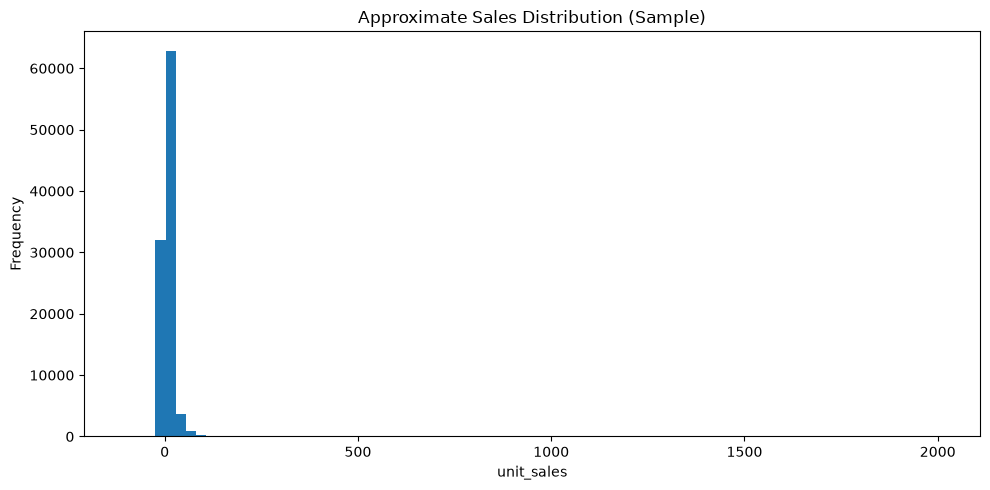

In [21]:
plt.figure(figsize=(10, 5))
plt.hist(target_sample, bins=80)
plt.xlabel("unit_sales")
plt.ylabel("Frequency")
plt.title("Approximate Sales Distribution (Sample)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_36112/1450499188.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target_sample, vert=False, showfliers=False)


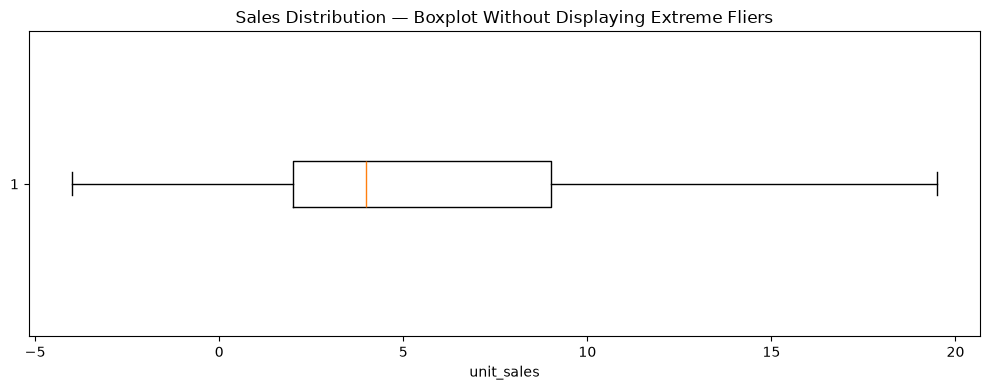

In [22]:
plt.figure(figsize=(10, 4))
plt.boxplot(target_sample, vert=False, showfliers=False)
plt.xlabel("unit_sales")
plt.title("Sales Distribution — Boxplot Without Displaying Extreme Fliers")
plt.tight_layout()
plt.show()

### Target Distribution — Interpretation

Ghi nhận:

- mức độ lệch phải/trái;
- tỷ lệ zero;
- vùng extreme values;
- liệu target transformation có đáng cân nhắc hay không.

**Chưa quyết định transformation ở notebook này.**

### 7.2 Time-based Analysis

**Questions:**

- Sales thay đổi theo thời gian như thế nào?
- Có trend không?
- Có seasonality theo tuần/tháng/năm không?
- Có giai đoạn bất thường không?

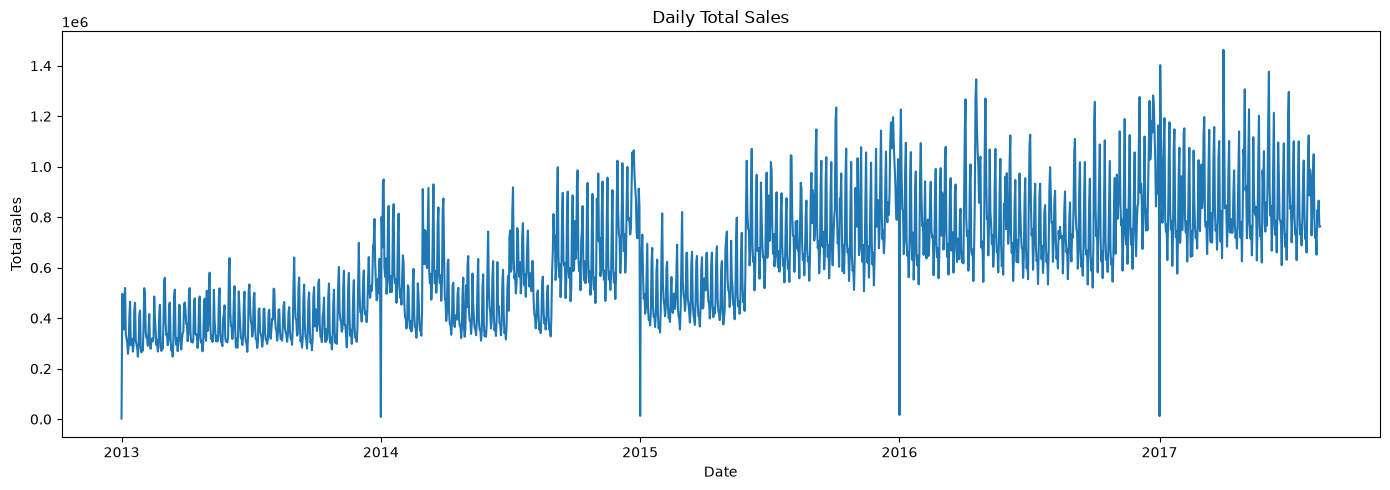

In [23]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales_df.index, daily_sales_df["unit_sales"])
plt.xlabel("Date")
plt.ylabel("Total sales")
plt.title("Daily Total Sales")
plt.tight_layout()
plt.show()

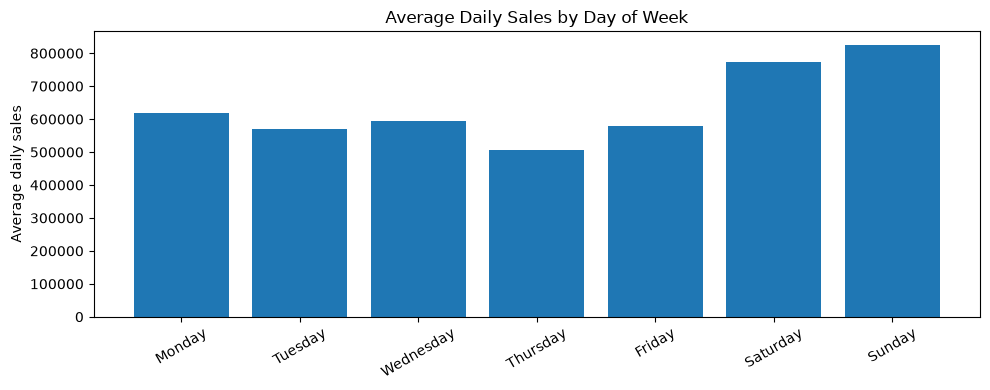

In [24]:
daily_eda = daily_sales_df.copy()
daily_eda["day_of_week"] = daily_eda.index.day_name()
daily_eda["month"] = daily_eda.index.month
daily_eda["year"] = daily_eda.index.year

dow_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

dow_sales = daily_eda.groupby("day_of_week")["unit_sales"].mean().reindex(dow_order)

plt.figure(figsize=(10, 4))
plt.bar(dow_sales.index, dow_sales.values)
plt.xticks(rotation=30)
plt.ylabel("Average daily sales")
plt.title("Average Daily Sales by Day of Week")
plt.tight_layout()
plt.show()

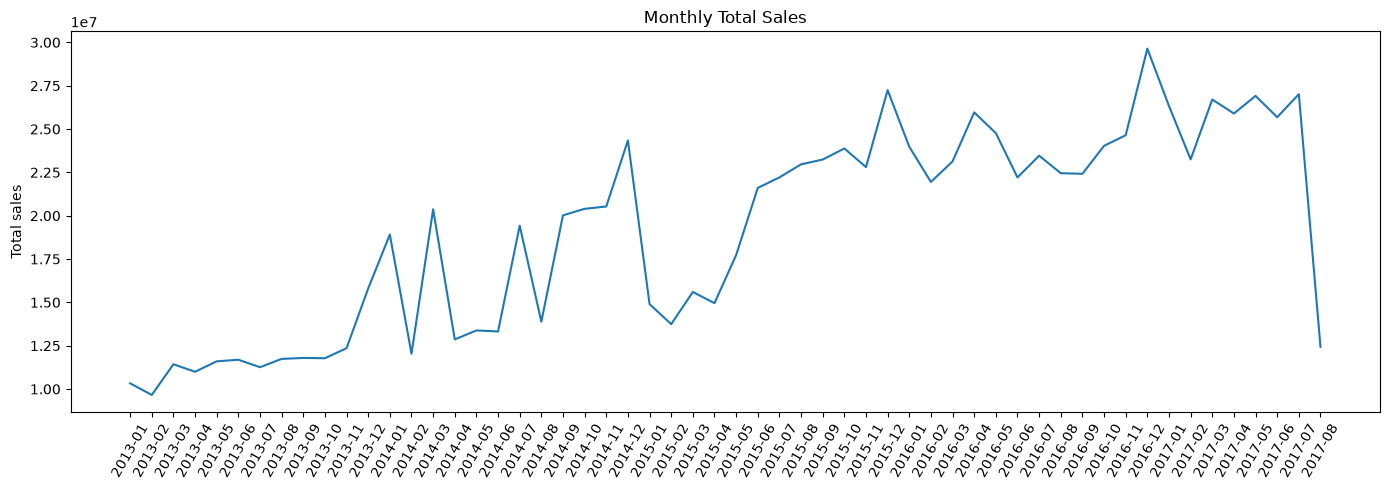

In [25]:
monthly_sales = daily_eda.groupby(
    [daily_eda.index.year, daily_eda.index.month]
)["unit_sales"].sum()

monthly_sales.index = [
    f"{year}-{month:02d}" for year, month in monthly_sales.index
]

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.xticks(rotation=60)
plt.ylabel("Total sales")
plt.title("Monthly Total Sales")
plt.tight_layout()
plt.show()

### Temporal EDA — Interpretation

Ghi nhận các pattern có thể ảnh hưởng đến feature engineering:

- trend;
- weekly seasonality;
- monthly/annual seasonality;
- unusual periods;
- possible structural changes.

### 7.3 Store Analysis

**Questions:**

- Doanh số phân bố giữa các store như thế nào?
- Một số store có đóng góp vượt trội không?
- Store metadata có thể giải thích khác biệt không?

In [26]:
store_sales = {}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["store_nbr", "unit_sales"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("store_nbr")["unit_sales"].sum()

    for store, value in grouped.items():
        store_sales[store] = store_sales.get(store, 0.0) + float(value)

store_sales_df = (
    pd.Series(store_sales, name="unit_sales")
    .sort_values(ascending=False)
    .to_frame()
)

store_sales_df.head(20)

,unit_sales
44,6.208754e+07
45,5.449801e+07
47,5.094831e+07
3,5.048190e+07
49,4.342009e+07
46,4.189605e+07
48,3.593313e+07
51,3.291148e+07
8,3.049134e+07
50,2.865302e+07


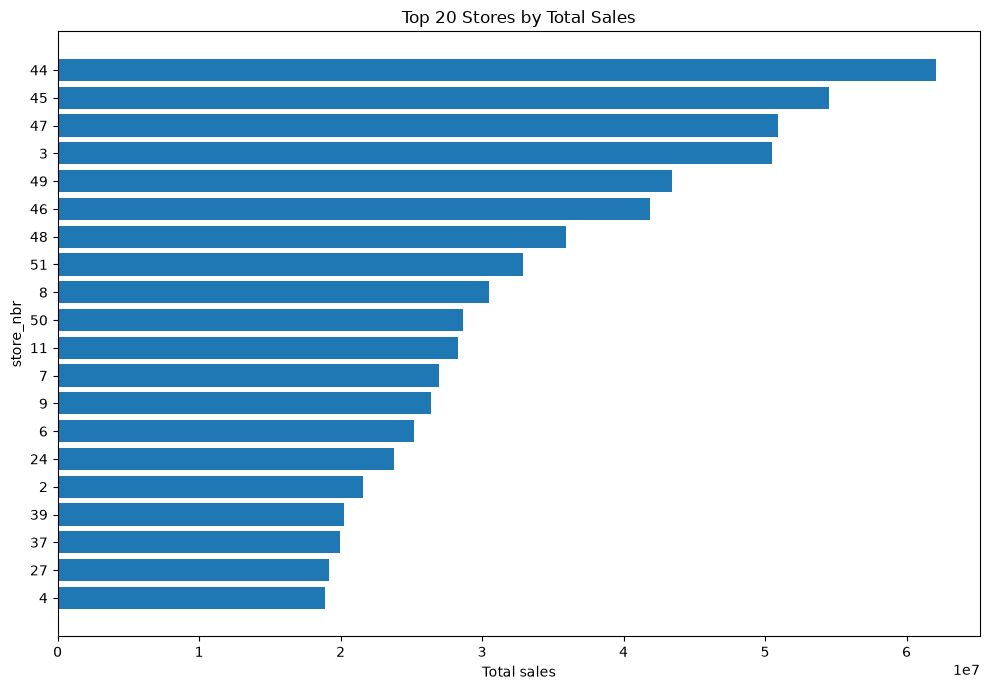

In [27]:
top_store = store_sales_df.head(20).sort_values("unit_sales")

plt.figure(figsize=(10, 7))
plt.barh(top_store.index.astype(str), top_store["unit_sales"])
plt.xlabel("Total sales")
plt.ylabel("store_nbr")
plt.title("Top 20 Stores by Total Sales")
plt.tight_layout()
plt.show()

### Store EDA — Interpretation

Ghi nhận:

- store concentration;
- khác biệt giữa store;
- khả năng cần store-level features;
- các store bất thường cần kiểm tra thêm.

### 7.4 Item Analysis

**Questions:**

- Những item nào đóng góp nhiều doanh số?
- Sales có tập trung vào một số item không?
- Item metadata có khả năng giải thích pattern không?

In [28]:
item_sales = {}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["item_nbr", "unit_sales"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("item_nbr")["unit_sales"].sum()

    for item, value in grouped.items():
        item_sales[item] = item_sales.get(item, 0.0) + float(value)

item_sales_df = (
    pd.Series(item_sales, name="unit_sales")
    .sort_values(ascending=False)
    .to_frame()
)

item_sales_df.head(20)

,unit_sales
1503844,6.264200e+06
1047679,5.512875e+06
1473474,4.990323e+06
364606,4.416426e+06
819932,4.410943e+06
1463992,4.408545e+06
807493,4.321424e+06
265559,4.112827e+06
502331,3.703350e+06
314384,3.544341e+06


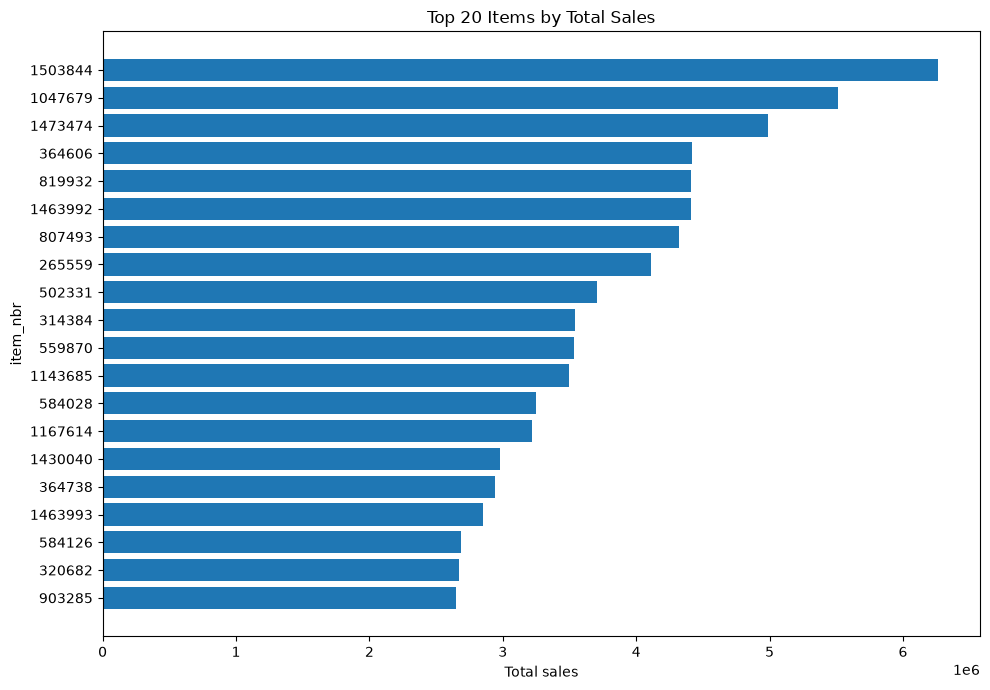

In [29]:
top_items = item_sales_df.head(20).sort_values("unit_sales")

plt.figure(figsize=(10, 7))
plt.barh(top_items.index.astype(str), top_items["unit_sales"])
plt.xlabel("Total sales")
plt.ylabel("item_nbr")
plt.title("Top 20 Items by Total Sales")
plt.tight_layout()
plt.show()

### Item EDA — Interpretation

Ghi nhận:

- item concentration;
- long-tail behavior;
- khả năng sử dụng item/category metadata;
- các item bất thường cần kiểm tra thêm.

### 7.5 Promotion Analysis

**Question:** Sales khác nhau như thế nào giữa các quan sát có và không có promotion?

Đây là exploratory comparison, **không phải causal analysis**.

In [30]:
promotion_stats = {
    True: {"rows": 0, "unit_sales": 0.0},
    False: {"rows": 0, "unit_sales": 0.0},
}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["unit_sales", "onpromotion"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("onpromotion")["unit_sales"].agg(["count", "sum"])

    for promo_value, row in grouped.iterrows():
        if pd.isna(promo_value):
            continue

        key = bool(promo_value)
        promotion_stats[key]["rows"] += int(row["count"])
        promotion_stats[key]["unit_sales"] += float(row["sum"])

promotion_df = pd.DataFrame(promotion_stats).T
promotion_df["mean_sales"] = promotion_df["unit_sales"] / promotion_df["rows"]
promotion_df

,rows,unit_sales,mean_sales
True,7810622.0,1.051830e+08,13.466666
False,96028767.0,7.766937e+08,8.088135


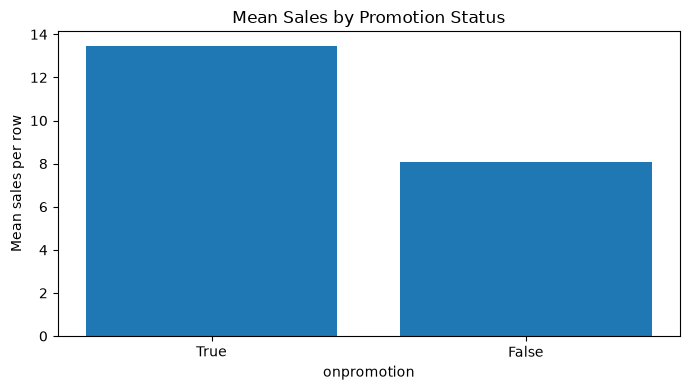

In [31]:
plt.figure(figsize=(7, 4))
plt.bar(
    promotion_df.index.astype(str),
    promotion_df["mean_sales"]
)
plt.xlabel("onpromotion")
plt.ylabel("Mean sales per row")
plt.title("Mean Sales by Promotion Status")
plt.tight_layout()
plt.show()

### Promotion EDA — Interpretation

So sánh này chỉ cho biết association trong dữ liệu quan sát được.

Không kết luận rằng promotion *gây ra* mức sales cao hơn.

### 7.6 Oil Analysis

Khảo sát oil price theo thời gian và so sánh với tổng sales theo ngày.

Oil columns: ['dcoilwtico']


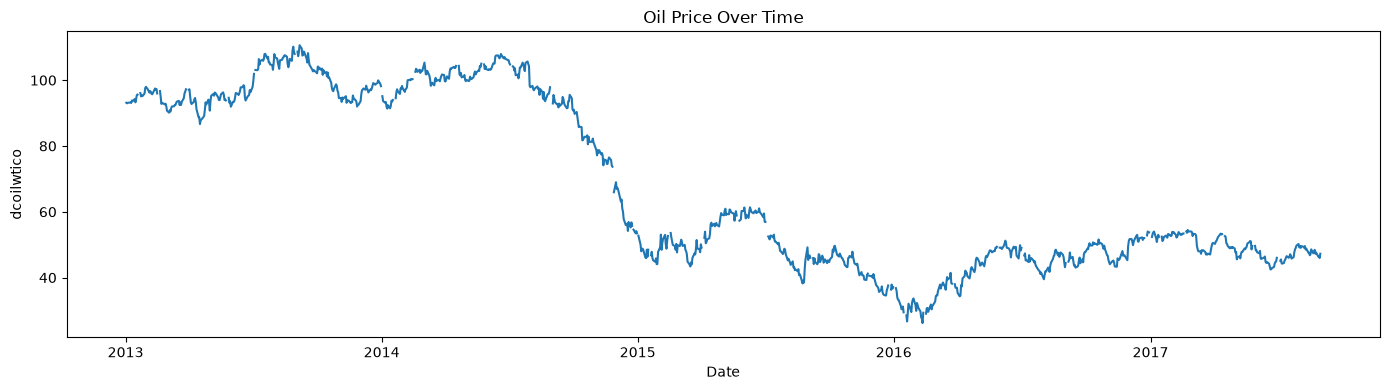

In [32]:
if "oil.csv" in small_tables:
    oil_df = small_tables["oil.csv"].copy()
    oil_df["date"] = pd.to_datetime(oil_df["date"], errors="coerce")

    oil_columns = [c for c in oil_df.columns if c != "date"]
    print("Oil columns:", oil_columns)

    if oil_columns:
        oil_col = oil_columns[0]

        plt.figure(figsize=(14, 4))
        plt.plot(oil_df["date"], oil_df[oil_col])
        plt.xlabel("Date")
        plt.ylabel(oil_col)
        plt.title("Oil Price Over Time")
        plt.tight_layout()
        plt.show()
else:
    print("oil.csv not available.")

### Oil EDA — Interpretation

Ghi nhận:

- temporal coverage;
- missing values;
- trend;
- khả năng sử dụng oil price như external feature.

Không tạo lag/imputation ở notebook này.

### 7.7 Holiday / Event Analysis

Khảo sát cấu trúc holiday/event và temporal coverage.

In [33]:
if "holidays_events.csv" in small_tables:
    holidays_df = small_tables["holidays_events.csv"].copy()
    holidays_df["date"] = pd.to_datetime(holidays_df["date"], errors="coerce")

    print("Rows:", len(holidays_df))
    display(holidays_df.head())

    for col in ["type", "locale", "locale_name", "transferred"]:
        if col in holidays_df.columns:
            print(f"\nValue counts: {col}")
            display(holidays_df[col].value_counts(dropna=False).head(20))
else:
    print("holidays_events.csv not available.")

Rows: 350


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False



Value counts: type


type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


Value counts: locale


locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


Value counts: locale_name


locale_name
Ecuador          174
Quito             13
Riobamba          12
Guaranda          12
Latacunga         12
Ambato            12
Guayaquil         11
Cuenca             7
Ibarra             7
Manta              6
Cotopaxi           6
Libertad           6
Puyo               6
Imbabura           6
Machala            6
Santo Domingo      6
El Carmen          6
Cayambe            6
Esmeraldas         6
Quevedo            6
Name: count, dtype: int64


Value counts: transferred


transferred
False    338
True      12
Name: count, dtype: int64

### Holiday/Event EDA — Interpretation

Xác định:

- loại event;
- phạm vi locale;
- transferred events;
- các đặc điểm có thể trở thành feature.

Chưa mã hóa hoặc biến đổi event ở đây.

### 7.8 Cross-variable Analysis

Kết hợp một số nguồn dữ liệu ở mức aggregate để tìm relationship đáng chú ý.

In [34]:
if "oil.csv" in small_tables:
    oil_df = small_tables["oil.csv"].copy()
    oil_df["date"] = pd.to_datetime(oil_df["date"], errors="coerce")

    oil_columns = [c for c in oil_df.columns if c != "date"]

    if oil_columns:
        oil_col = oil_columns[0]

        cross_df = daily_sales_df.reset_index().rename(columns={"index": "date"})
        cross_df = cross_df.merge(
            oil_df[["date", oil_col]],
            on="date",
            how="left"
        )

        display(cross_df[["date", "unit_sales", oil_col]].head())

        print("Correlation on available paired dates:")
        display(cross_df[["unit_sales", oil_col]].corr())
else:
    print("Skipping sales × oil analysis because oil.csv is unavailable.")

,date,unit_sales,dcoilwtico
0,2013-01-01,2511.619,NaN
1,2013-01-02,496092.418,93.14
2,2013-01-03,361429.231,92.97
3,2013-01-04,354459.677,93.12
4,2013-01-05,477350.121,NaN


Correlation on available paired dates:


,unit_sales,dcoilwtico
unit_sales,1.000000,-0.705029
dcoilwtico,-0.705029,1.000000


### Cross-variable EDA — Interpretation

Correlation is descriptive and may be affected by trend, seasonality, promotions and other confounding factors.

Feature engineering should consider temporal alignment and lag structure rather than using contemporaneous relationships blindly.

## 8. Memory & Data Processing Findings

Đối chiếu kết quả EDA với resource constraints từ notebook `00`.

Mục tiêu:

- xác nhận các thao tác thực tế có phù hợp với RAM;
- ghi nhận các thao tác cần chunking;
- tránh thiết kế pipeline dựa trên giả định rằng toàn bộ train có thể nằm trong RAM.

In [35]:
if psutil is not None:
    mem = psutil.virtual_memory()
    print(f"Current available RAM: {mem.available / (1024**3):.2f} GB")
    print(f"Current RAM usage: {mem.percent:.1f}%")

largest_file = file_inventory_df.iloc[0]
print(f"Largest raw file: {largest_file['file']}")
print(f"Largest raw file size: {largest_file['size_mb'] / 1024:.2f} GB")
print(f"Working chunk size: {DEFAULT_CHUNK_SIZE:,} rows")

Current available RAM: 2.57 GB
Current RAM usage: 65.7%
Largest raw file: train.csv
Largest raw file size: 4.65 GB
Working chunk size: 100,000 rows


### Resource Findings

Tổng hợp thực tế:

- `train.csv` là dataset lớn nhất.
- Full-data DataFrame không được giả định là an toàn trên máy hiện tại.
- Chunk-based aggregation phù hợp cho thống kê và EDA quy mô lớn.
- Reference tables nhỏ có thể load full nếu nằm trong giới hạn tài nguyên.
- Các bước cleaning/feature engineering phải tránh tạo nhiều bản sao của train.

## 9. EDA Conclusions & Next-step Decisions

Phần này là cầu nối từ `01_eda.ipynb` sang `02_data_cleaning.ipynb`.

Không chỉ liệt kê biểu đồ; cần chuyển phát hiện thành vấn đề cần xử lý.

In [36]:
eda_summary = {
    "raw_files": len(csv_files),
    "train_rows": int(
        shape_df.loc[shape_df["file"] == "train.csv", "rows"].iloc[0]
    ) if "train.csv" in shape_df["file"].values else None,
    "train_date_min": str(train_min) if train_min is not None else None,
    "train_date_max": str(train_max) if train_max is not None else None,
    "target_zero_pct": float(target_summary["zero_pct"]),
    "target_negative_pct": float(target_summary["negative_pct"]),
    "train_duplicate_rows_within_chunks": int(
        train_duplicate_result["duplicate_rows_within_chunks"]
    ),
    "chunk_size": DEFAULT_CHUNK_SIZE,
}

pd.Series(eda_summary)

raw_files                                               8
train_rows                                      125497040
train_date_min                        2013-01-01 00:00:00
train_date_max                        2017-08-15 00:00:00
target_zero_pct                                       0.0
target_negative_pct                              0.006211
train_duplicate_rows_within_chunks                      0
chunk_size                                         100000
dtype: object

### 9.1 Data Quality Findings

Cập nhật sau khi chạy hoàn chỉnh:

- Missing values:
- Duplicate records:
- Invalid values:
- Referential integrity:
- Date validity:
- Other anomalies:

Các vấn đề này sẽ được xử lý có chủ đích trong `02_data_cleaning.ipynb`.

### 9.2 Temporal Findings

Ghi nhận:

- Train date range:
- Test date range:
- Missing calendar dates:
- Trend:
- Weekly seasonality:
- Monthly/yearly patterns:
- Unusual periods:

Các phát hiện này sẽ ảnh hưởng đến validation và feature engineering.

### 9.3 Target Findings

Ghi nhận:

- Distribution:
- Zero-sales rate:
- Negative-sales rate:
- Extreme values:
- Potential transformation considerations:

Không thực hiện target transformation trong notebook này.

### 9.4 Decisions for `02_data_cleaning.ipynb`

Danh sách quyết định phải xuất phát từ bằng chứng ở trên.

Ví dụ:

1. Chuẩn hóa `date` thành datetime.
2. Xử lý missing values theo từng column/domain.
3. Xử lý duplicate theo business key nếu xác nhận được.
4. Xác định cách xử lý các giá trị bất thường.
5. Chuẩn hóa các reference keys.
6. Giữ pipeline chunk-safe cho `train.csv`.
7. Không sửa trực tiếp files trong `data/raw/`.

## Conclusion

`01_eda.ipynb` hoàn thành hai nhiệm vụ:

1. **Data Validation:** xác định dữ liệu có hợp lệ và nhất quán đến mức nào.
2. **EDA:** hiểu target, temporal structure, store, item, promotion và external variables.

Notebook tiếp theo:

`02_data_cleaning.ipynb`

sẽ thực hiện các quyết định xử lý dữ liệu đã được chứng minh và ghi nhận ở notebook này.